Basic ML (1 real input and 1 real output) - Polinomial regression + Regularization

In [240]:
import numpy as np # numerical things
import numpy.matlib as nml # matricial computations
import matplotlib.pyplot as plt # plots

In [241]:
np.random.seed(13)

In [242]:
def oracle(x):
  return x**2

In [243]:
n = 5
sigma = 1
nt = 1000

In [244]:
x = np.random.rand(n)
y = oracle(x) + sigma * np.random.randn(n)
xt = np.linspace(0,1,nt)
yt = oracle(xt)

In [245]:
x = np.asmatrix(x).transpose()
y = np.asmatrix(y).transpose()
xt = np.asmatrix(xt).transpose()
yt = np.asmatrix(yt).transpose()

In [246]:
# We want to see what happens to the error of the model varying the value of p

for p in range(0,5):
  X = nml.ones((n,1))
  Xt = nml.ones((nt,1))
  for i in range (1, p+1):
    X = np.concatenate((X,np.power(x,i)), axis=1)
    Xt = np.concatenate((Xt,np.power(xt,i)), axis=1)
  c = np.linalg.solve(np.matmul(np.transpose(X),X), np.matmul(np.transpose(X),y))
  yp = np.matmul(Xt,c)
  err = np.mean(np.power(yt-yp,2))
  print(str(p), "", str(err))

0  0.8514299248944304
1  0.4471341862339436
2  3.3485122449706664
3  188.15515786659623
4  214295.50824939637


Examples

1. Parameters: n = 5, sigma = 0.2, nt = 1000. Best p = 1 (error 0.3649515286101964)

2. Parameters: n = 5, sigma = 10, nt = 1000. Best p = 0 (error 35.34924028036181).

    - I'm not happy bc the error is high, but it's the best result we can get with this scenario. Good: the model is simple.

    - On an oracle of degree 2, the best model is found for p = 0 -> not happy : knowing something about the system in practice is completely USELESS.

    - In this case, highering the value of p makes the situation worse and worse. My data are pure NOISE, so they cannot be fitted.

    The important thing is not how much I've learnt form the data, but how much information I can extract from it. I am working in a perfect world (perfect hypotesis), with idd samples, pure random. In this case the noise corrupting my data can destroy the info that is present in the data -> I can use the wrong model but a very simple one -> useless to know something about the system.

3. Parameters: n =  5, sigma = 1, nt = 1000. Best p = 1 (error 0.4471341862339436).

    - Reducing the noise has improve my ability to learn more complex model.
    

Whituout any noise, any parameter n and nt will give me as best p = 2; in fact, the oracle will be the best model aproximation (quite equal to the exact model). Also if I higher p, the results will be good, but my model will be more complex and I will not get additional info wrt to the case in which p = 2.

Here we can see the difference between math and ML: wrong models can be the correct ones. I do not have the ability to know which model is the best one -> the only thing I can do is to try. In math we use Taylor series because the more terms we have, the happier we are (model best aprox). In ML I want a correct model, but also a SIMPLE one.

NB: using the same sigma, the more samples we have, the less the noise affects the data

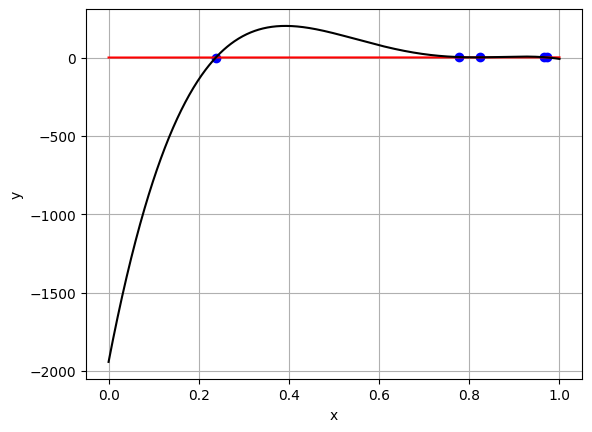

In [247]:
fig, ax = plt.subplots()
ax.plot(x,y, 'bo') # blue points
ax.plot(xt,yt, 'r') # red line for the model we created
ax.plot(xt,yp, 'k') # black line for what we actually have learnt
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid() # acrivate the grid
plt.show()